In [125]:
import os 
from pathlib import Path
from dotenv import load_dotenv

import pandas as pd 
load_dotenv(override=True)

import matplotlib.pyplot as plt

In [126]:
data_repo_env = os.getenv("DATA_REPO_PATH")
DATA_REPO_DIR = Path(data_repo_env)

playermatchstats = DATA_REPO_DIR / "GW5" / "playermatchstats.csv"
teams = DATA_REPO_DIR / "GW5" / "teams.csv"
players = DATA_REPO_DIR / "GW5" / "players.csv"

In [127]:
gw5_player = pd.read_csv(playermatchstats)
player_ids = pd.read_csv(players)
team_codes = pd.read_csv(teams)

In [128]:
gw5_player["team_code"] = gw5_player["player_id"].map(
    player_ids.set_index("player_id")["team_code"]
)

gw5_player["team_name"] = gw5_player["team_code"].map(
    team_codes.set_index("code")["short_name"]
)

In [129]:
gw5_workrate = gw5_player.groupby("team_name").agg({
    'number_of_sprints': 'sum',
    'sprinting_distance': 'sum'
}).reset_index()

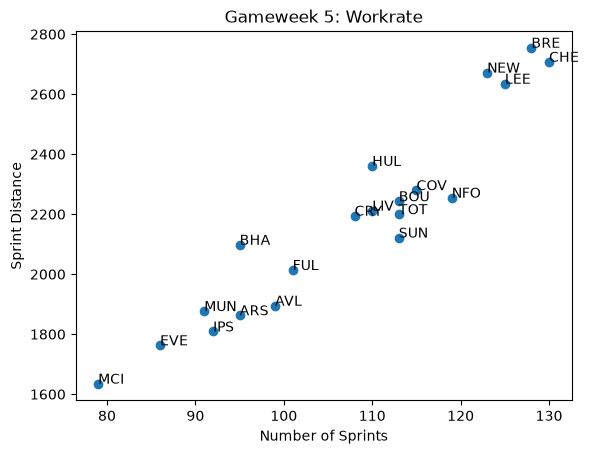

In [130]:
plt.scatter(gw5_workrate["number_of_sprints"], gw5_workrate["sprinting_distance"])
plt.title("Gameweek 5: Workrate")
plt.xlabel("Number of Sprints")
plt.ylabel("Sprint Distance")

for _, row in gw5_workrate.iterrows():
    plt.annotate(
        row["team_name"],
        (row["number_of_sprints"], row["sprinting_distance"])
    )


In [131]:
gws = []

for i in range(1,6):
    path_stats = DATA_REPO_DIR / f"GW{i}" / "playermatchstats.csv"
    path_players = DATA_REPO_DIR / f"GW{i}" / "players.csv"
    gw_it = pd.read_csv(path_stats)
    players_it = pd.read_csv(path_players)

    gw_it["team_code"] = gw_it["player_id"].map(
        players_it.set_index("player_id")["team_code"]
    )
    gw_it["team_name"] = gw_it["team_code"].map(
        team_codes.set_index("code")["short_name"]
    )
    gws.append(gw_it)

gw_players = pd.concat(
    [gw[['team_name', 'number_of_sprints', 'sprinting_distance']] for gw in gws],
    ignore_index=True
)

In [132]:
gw_players

,team_name,number_of_sprints,sprinting_distance
0,FUL,NaN,NaN
1,FUL,NaN,NaN
2,BRE,NaN,NaN
3,CRY,NaN,NaN
4,EVE,NaN,NaN
...,...,...,...
1991,MCI,16.0,312.0
1992,SUN,14.0,245.0
1993,MCI,1.0,7.0
1994,SUN,11.0,174.0


In [133]:
gw_workrate = gw_players.groupby("team_name").agg({
    'number_of_sprints':'sum',
    'sprinting_distance':'sum'
}).reset_index()

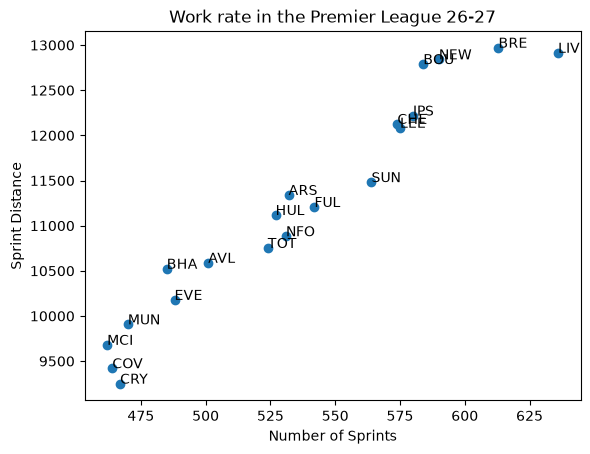

In [135]:
plt.scatter(gw_workrate["number_of_sprints"], gw_workrate["sprinting_distance"])
plt.title("Work rate in the Premier League 26-27")
plt.xlabel("Number of Sprints")
plt.ylabel("Sprint Distance")

for _, row in gw_workrate.iterrows():
    plt.annotate(
        row["team_name"],
        (row["number_of_sprints"], row["sprinting_distance"])
    )


In [139]:
gw_workrate.sort_values(by="number_of_sprints", ascending=False)

,team_name,number_of_sprints,sprinting_distance
13,LIV,636.0,12915.0
4,BRE,613.0,12971.0
16,NEW,590.0,12842.0
3,BOU,584.0,12789.0
11,IPS,580.0,12219.0
12,LEE,575.0,12085.0
5,CHE,574.0,12127.0
18,SUN,564.0,11482.0
9,FUL,542.0,11207.0
0,ARS,532.0,11340.0
